# Question for Day 8

Consider the diffusion and simultaneous first order irreversible homogeneous chemical reaction in a single phase containing only reactant A and product B. The governing equation is:

$$
\frac{\partial^2C_\text{A}}{\partial z^2} = \frac{k}{D_\text{AB}}C_\text{A}
$$

where, $C_\text{A}$ is the concentration of reactant A ($\frac{\text{kg} \cdot \text{mol}}{m^{-3}}$), $z$ is the distance variable, $k$ is the reaction rate constant ($s^{-1}$) and $D_\text{AB}$ is the binary diffusion coefficient ($m^2 s^{-1}$)
The boundary conditions are:

$$
z = 0: C_\text{A} = C_{\text{A},0} \\
z = L: \frac{\partial C_\text{A}}{\partial z} = 0
$$

1. Numerically solve for $C_\text{A}$ for $C_{\text{A},0}=0.2 \, \text{kg} \cdot \text{mol} \cdot \text{m}^{-3}$, $k=10^{-3} \, \text{s}^{-1}$, $D_\text{AB}= 1.2 \times 10^{-9} \, \text{m}^2 \text{s}^{-1}$.
2. Validate your code by comparing numerical concentration profile with the analytical solution.
3. Plot the rms error for different number of grids and find the required grid density.

\newpage

## Analysis and Inputs

- Writing $m^2 = k/D_\text{AB}$, the governing equation becomes $\dfrac{d^2C_\text{A}}{dz^2} = m^2 C_\text{A}$, a linear second-order ODE with a Dirichlet condition at $z=0$ and a Neumann (no-flux) condition at $z=L$. Its analytical solution is
  $$
  C_\text{A}(z) = C_{\text{A},0}\,\frac{\cosh\!\left[m(L-z)\right]}{\cosh(mL)}
  $$
  which satisfies $C_\text{A}(0) = C_{\text{A},0}$ and has zero slope at $z=L$ because $\sinh(0) = 0$.
- The problem statement does not give the length $L$ of the medium, so it is taken as an input. We use $L = 5\ \text{mm}$, which gives $mL \approx 4.56$: the reaction depletes $\text{A}$ within a penetration depth $1/m \approx 1.1\ \text{mm}$, so the profile decays steeply near $z=0$ and flattens at the closed end $z=L$.
- The domain is divided into $N$ uniform intervals of width $h = L/N$, with nodes $z_i = ih$, $i = 0, 1, \dots, N$. Replacing the second derivative with a second-order central difference gives, for every interior node,
  $$
  \frac{C_{i-1} - 2C_i + C_{i+1}}{h^2} = m^2 C_i \quad\implies\quad C_{i-1} - \left(2 + m^2h^2\right)C_i + C_{i+1} = 0
  $$
- At $z=0$, $C_0 = C_{\text{A},0}$ is known, so for $i=1$ it is moved to the right-hand side: $-\left(2+m^2h^2\right)C_1 + C_2 = -C_{\text{A},0}$.
- At $z=L$, the zero-gradient condition is applied with a central difference using a ghost node, $\frac{C_{N+1} - C_{N-1}}{2h} = 0 \implies C_{N+1} = C_{N-1}$. Substituting into the equation for $i = N$ gives $2C_{N-1} - \left(2+m^2h^2\right)C_N = 0$. This keeps the boundary treatment second-order accurate, unlike a one-sided difference.
- The unknowns $C_1, \dots, C_N$ therefore satisfy a tri-diagonal system $a_iC_{i-1} + b_iC_i + c_iC_{i+1} = d_i$ with
  $$
  a_i = 1\ (a_N = 2), \qquad b_i = -\left(2 + m^2h^2\right), \qquad c_i = 1, \qquad d_1 = -C_{\text{A},0},\ d_{i>1} = 0
  $$
  which is solved with the TDMA described in Appendix A. The matrix is diagonally dominant, $|b_i| \ge |a_i| + |c_i|$, so the algorithm is stable without pivoting.
- The error is measured by the root-mean-square difference over all nodes,
  $$
  \text{rms} = \sqrt{\frac{1}{N+1}\sum_{i=0}^{N}\left[C_i - C_\text{A}(z_i)\right]^2}
  $$
  Since the truncation error is $\mathcal{O}(h^2)$, the rms error is expected to fall by a factor of 4 each time $N$ is doubled. The required grid is the coarsest one in the sequence $N = 4, 8, 16, \dots$ for which the rms error drops below a user-specified tolerance.

\newpage

## User Input

We read certain inputs from the user, defined in a file:

```yaml
C_A0: 0.2        # kgmol/m^3
k: 1e-3          # 1/s
D_AB: 1.2e-9     # m^2/s
L: 5e-3          # m
N: 20            # intervals for the demonstration solution
rms_tol: 1e-5    # kgmol/m^3
```

In [1]:
fprintf("--- INPUT ---\n");
[~, data] = readvars("input.txt", "TextType", "string");
C_A0 = data(1); k = data(2); D_AB = data(3); L = data(4);
N_demo = data(5); rms_tol = data(6);

m = sqrt(k / D_AB);   % m^-1
analytical = @(z) C_A0 * cosh(m * (L - z)) / cosh(m * L);

fprintf("C_A0 = %g kgmol/m^3, k = %g 1/s, D_AB = %g m^2/s, L = %g m\n", ...
    C_A0, k, D_AB, L);
fprintf("m = sqrt(k/D_AB) = %.2f 1/m, 1/m = %.3f mm, m*L = %.3f\n", ...
    m, 1e3 / m, m * L);
fprintf("Grid: N = %d intervals, tolerance: rms < %g kgmol/m^3\n", ...
    N_demo, rms_tol);

--- INPUT ---
C_A0 = 0.2 kgmol/m^3, k = 0.001 1/s, D_AB = 1.2e-09 m^2/s, L = 0.005 m
m = sqrt(k/D_AB) = 912.87 1/m, 1/m = 1.095 mm, m*L = 4.564
Grid: N = 20 intervals, tolerance: rms < 1e-05 kgmol/m^3


\newpage

## Algorithm

- **Step 01.** **START**
- **Step 02.** Inputs:

| Variable           | Description                                      |
| ------------------ | ------------------------------------------------ |
| $C_{\text{A},0}$   | Concentration at $z=0$                           |
| $k$, $D_\text{AB}$ | Reaction rate constant and diffusion coefficient |
| $L$                | Length of the domain                             |
| $N$                | Number of grid intervals                         |

- **Step 03.** Compute $h = L/N$ and $m^2h^2 = \dfrac{k}{D_\text{AB}}h^2$
- **Step 04.** Build the tri-diagonal coefficients for the unknowns $C_1, \dots, C_N$:
  - **Step 05.** $a_i = 1$ (with $a_N = 2$), $b_i = -(2 + m^2h^2)$, $c_i = 1$
  - **Step 06.** $d_1 = -C_{\text{A},0}$ and $d_i = 0$ for $i = 2, \dots, N$
- **Step 07.** Solve $a_iC_{i-1} + b_iC_i + c_iC_{i+1} = d_i$ using the TDMA (Appendix A)
- **Step 08.** Set $C_0 = C_{\text{A},0}$ and assemble $\textbf{C} = [C_0, C_1, \dots, C_N]^T$
- **Step 09.** Outputs:

| Variable | Description                      |
| -------- | -------------------------------- |
| $z_i$    | Grid points                      |
| $C_i$    | Concentration at the grid points |

- **Step 10.** For the grid study, repeat Steps 03 to 09 for $N = 4, 8, 16, \dots$, compute the rms error against the analytical solution each time, and stop at the first $N$ where $\text{rms} <$ tolerance
- **Step 11.** **STOP**

\newpage

## Implementation

The function below uses `tdma.m`, which is defined in Appendix A.

In [ ]:
%%file diffusion_reaction_fd.m
function [z, C] = diffusion_reaction_fd(C_A0, k, D_AB, L, N) %#ok<FNDEF>
    h = L / N; z = linspace(0, L, N + 1)';
    m2h2 = (k / D_AB) * h^2;

    % Unknowns: C_1, ..., C_N (C_0 = C_A0 is known)
    a = ones(N, 1); b = -(2 + m2h2) * ones(N, 1);
    c = ones(N, 1); d = zeros(N, 1);

    d(1) = -C_A0;   % z = 0: Dirichlet boundary moved to the RHS
    a(N) = 2;       % z = L: ghost node C_{N+1} = C_{N-1} (zero gradient)

    C = [C_A0; tdma(a, b, c, d)];
end

File diffusion_reaction_fd.m created successfully.

## Solution

The concentration profile is solved on the demonstration grid ($N = 20$) defined in the input file.

--- OUTPUT ---
    z (mm) C_A (kgmol/m^3)
     0.000       0.200000
     0.250       0.159279
     0.500       0.126853
     0.750       0.101035
     1.000       0.080478
     1.250       0.064114
     1.500       0.051088
     1.750       0.040724
     2.000       0.032480
     2.250       0.025928
     2.500       0.020727
     2.750       0.016605
     3.000       0.013347
     3.250       0.010785
     3.500       0.008785
     3.750       0.007242
     4.000       0.006077
     4.250       0.005228
     4.500       0.004651
     4.750       0.004317
     5.000       0.004207


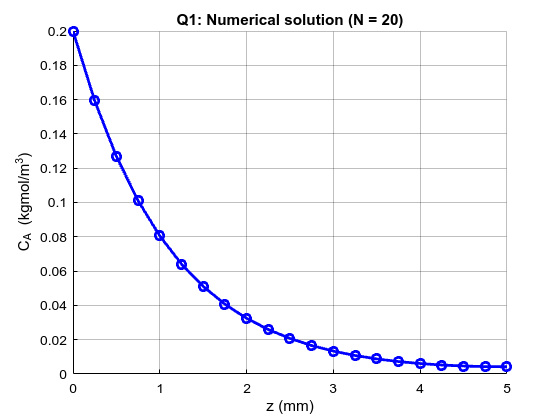

In [7]:
fprintf("--- OUTPUT ---\n");
[z, C_num] = diffusion_reaction_fd(C_A0, k, D_AB, L, N_demo);
fprintf("%10s %14s\n", "z (mm)", "C_A (kgmol/m^3)");
fprintf("%10.3f %14.6f\n", [z * 1e3, C_num]');

figure('Color', 'w'); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(z * 1e3, C_num, 'bo-', 'LineWidth', 2);
hold off; xlabel('z (mm)'); ylabel('C_A (kgmol/m^3)');
title(sprintf('Q1: Numerical solution (N = %d)', N_demo), 'Color', 'k');

\newpage

N = 20: rms error = 1.0149e-04 kgmol/m^3 (0.0507 % of C_A0)
Max |error| = 1.5903e-04 kgmol/m^3 at z = 1.000 mm


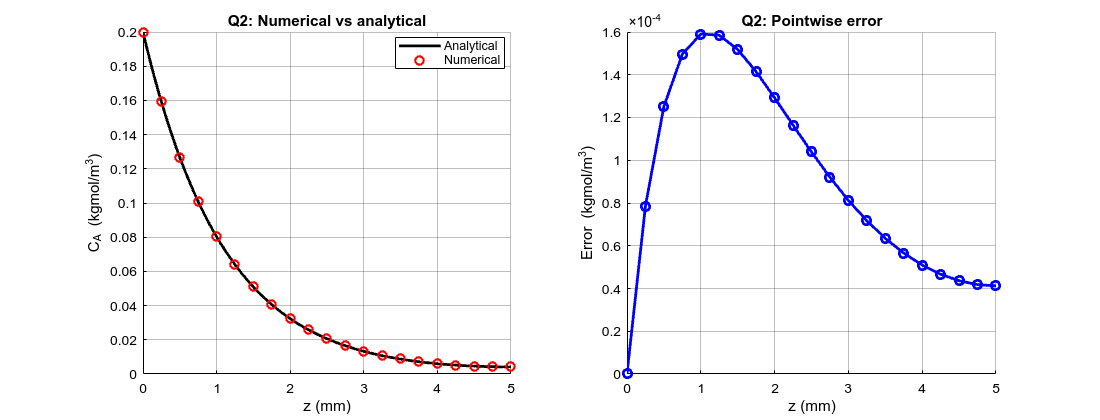

In [ ]:
z_fine = linspace(0, L, 500)';
rms_demo = sqrt(mean((C_num - analytical(z)).^2));
fprintf("N = %d: rms error = %.4e kgmol/m^3 (%.4f %% of C_A0)\n", ...
    N_demo, rms_demo, 100 * rms_demo / C_A0);
fprintf("Max |error| = %.4e kgmol/m^3 at z = %.3f mm\n", ...
    max(abs(C_num - analytical(z))), ...
    1e3 * z(abs(C_num - analytical(z)) == ...
    max(abs(C_num - analytical(z)))));

figure('Color', 'w', 'Position', [100, 100, 1100, 420]);
subplot(1,2,1); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(z_fine * 1e3, analytical(z_fine), 'k-', 'LineWidth', 2);
plot(z * 1e3, C_num, 'ro', 'LineWidth', 1.5);
hold off; xlabel('z (mm)'); ylabel('C_A (kgmol/m^3)');
title('Q2: Numerical vs analytical', 'Color', 'k');
legend('Analytical', 'Numerical', 'Location', 'best', ...
    'TextColor', 'k', 'Color', 'w', 'EdgeColor', 'k');

subplot(1,2,2); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
plot(z * 1e3, C_num - analytical(z), 'b-o', 'LineWidth', 2);
hold off; xlabel('z (mm)'); ylabel('Error (kgmol/m^3)');
title('Q2: Pointwise error', 'Color', 'k');

     N        h (m)      rms error
     4   1.2500e-03     2.0798e-03
     8   6.2500e-04     6.0045e-04
    16   3.1250e-04     1.5735e-04
    32   1.5625e-04     4.0076e-05
    64   7.8125e-05     1.0102e-05
   128   3.9063e-05     2.5352e-06
   256   1.9531e-05     6.3497e-07
   512   9.7656e-06     1.5889e-07
  1024   4.8828e-06     3.9740e-08
  2048   2.4414e-06     9.9366e-09
  4096   1.2207e-06     2.4817e-09

Required grid for rms < 1e-05 kgmol/m^3:
    N = 128 intervals (129 nodes), h = 3.906e-05 m


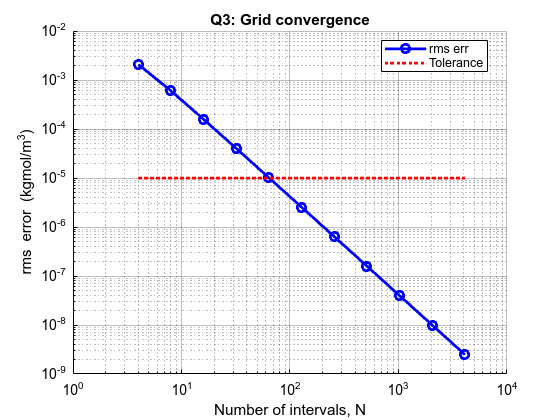

In [2]:
Ns = 4 * 2.^(0:10)';
rms_err = zeros(size(Ns));

for j = 1:numel(Ns)
    [z_j, C_j] = diffusion_reaction_fd(C_A0, k, D_AB, L, Ns(j));
    rms_err(j) = sqrt(mean((C_j - analytical(z_j)).^2));
end

idx = find(rms_err < rms_tol, 1); % first grid meeting the tolerance
N_req = Ns(idx); h_req = L / N_req;

fprintf("%6s %12s %14s\n", "N", "h (m)", "rms error");
for j = 1:numel(Ns)
    fprintf("%6d %12.4e %14.4e\n", Ns(j), L / Ns(j), rms_err(j));
end
fprintf("\nRequired grid for rms < %g kgmol/m^3:\n", rms_tol);
fprintf("    N = %d intervals (%d nodes), h = %.3e m\n", N_req, ...
    N_req + 1, h_req);

figure('Color', 'w'); hold on; grid on;
set(gca, 'Color', 'w', 'XColor', 'k', 'YColor', 'k', ...
    'XScale', 'log', 'YScale', 'log');
plot(Ns, rms_err, 'bo-', 'LineWidth', 2);
plot(Ns, rms_tol * ones(size(Ns)), 'r:', 'LineWidth', 2);
hold off;
xlabel('Number of intervals, N'); ylabel('rms error (kgmol/m^3)');
title('Q3: Grid convergence', 'Color', 'k');
legend('rms err', 'Tolerance', 'Location', 'best', 'TextColor', 'k', ...
    'Color', 'w', 'EdgeColor', 'k');

\newpage

## Discussion

The governing equation for steady diffusion with a first-order homogeneous reaction was solved with a second-order central-difference scheme, and the resulting tri-diagonal system was solved with the TDMA. With $m = \sqrt{k/D_\text{AB}} \approx 913\ \text{m}^{-1}$. For the assumed length $L = 5\ \text{mm}$ ($mL \approx 4.56$), the concentration of $\text{A}$ falls steeply from $0.2\ \text{kg}\cdot\text{mol}\cdot\text{m}^{-3}$ at $z=0$, and at the closed end it is only about $0.004$, roughly 2 % of the surface value. The curve flattens there, consistent with the zero-gradient boundary condition.

For validation, the profile on the $N=20$ grid agrees closely with the analytical $\cosh$ solution. The rms error is $1.0 \times 10^{-4}\ \text{kg}\cdot\text{mol}\cdot\text{m}^{-3}$ (about 0.05 % of $C_{\text{A},0}$). The pointwise error is largest, at $1.6 \times 10^{-4}$, about $1\ \text{mm}$ from the surface, where the curvature of the profile is greatest, and it is zero at $z=0$ by construction.

In the grid study, the rms error falls by a factor of almost exactly 4 for every doubling of $N$. Taking a tolerance of $10^{-5}\ \text{kg}\cdot\text{mol}\cdot\text{m}^{-3}$ on the rms error, $N=64$ narrowly misses ($1.01 \times 10^{-5}$) and $N=128$ is the first grid that meets it ($2.5 \times 10^{-6}$). The required grid therefore has $h \approx 39\ \mu\text{m}$.

# Appendix A: Tri-diagonal Matrix Algorithm

To solve a system of simultaneous algebraic equations with nonzero coefficients only on the main diagonal, the lower diagonal, and the upper diagonal, we employ the more efficient, $\mathcal{O}(n)$ Tri-diagonal Matrix Algorithm (TDMA). It states that for a system of equations of the form:

$$
a_i x_{i-1} + b_i x_i + c_i x_{i+1} = d_i, \quad i = 1, 2, \dots, n
$$

It solves the system of equations by forward elimination and back substitution:

Here $a_1$ and $c_n$ are not used. The algorithm works in two sweeps. In the forward sweep, the sub-diagonal is eliminated by computing modified coefficients

$$
c'_1 = \frac{c_1}{b_1}, \quad d'_1 = \frac{d_1}{b_1}, \qquad c'_i = \frac{c_i}{b_i - a_i c'_{i-1}}, \quad d'_i = \frac{d_i - a_i d'_{i-1}}{b_i - a_i c'_{i-1}}, \quad i = 2, \dots, n
$$

and in the back substitution, the solution is recovered starting from the last unknown:

$$
x_n = d'_n, \qquad x_i = d'_i - c'_i x_{i+1}, \quad i = n-1, \dots, 1
$$

Each sweep visits every row once, so the cost is $\mathcal{O}(n)$ in both operations and storage, compared with $\mathcal{O}(n^3)$ for general Gaussian elimination. The algorithm is stable without pivoting when the matrix is diagonally dominant, $|b_i| \ge |a_i| + |c_i|$, which holds for the finite difference system in this report.

### Algorithm

- **Step 01.** **START**
- **Step 02.** Inputs: vectors $\textbf{a}$, $\textbf{b}$, $\textbf{c}$ (the three diagonals) and $\textbf{d}$ (right-hand side)
- **Step 03.** Compute $c'_1 = c_1/b_1$ and $d'_1 = d_1/b_1$
- **Step 04.** For $i = 2, \dots, n$ compute $c'_i$ and $d'_i$ (forward sweep)
- **Step 05.** Set $x_n = d'_n$
- **Step 06.** For $i = n-1, \dots, 1$ compute $x_i = d'_i - c'_i x_{i+1}$ (back substitution)
- **Step 07.** Output $\textbf{x}$
- **Step 08.** **STOP**

### Implementation


In [ ]:
%%file tdma.m
function x = tdma(a, b, c, d) %#ok<FNDEF>
    n = numel(d);
    c_star = zeros(n, 1); d_star = zeros(n, 1); x = zeros(n, 1);

    % Forward sweep
    c_star(1) = c(1) / b(1);
    d_star(1) = d(1) / b(1);
    for i = 2:n
        denom = b(i) - a(i) * c_star(i-1);
        c_star(i) = c(i) / denom;
        d_star(i) = (d(i) - a(i) * d_star(i-1)) / denom;
    end

    % Back substitution
    x(n) = d_star(n);
    for i = n-1:-1:1
        x(i) = d_star(i) - c_star(i) * x(i+1);
    end
end

File tdma.m created successfully.